# Open water: EODs my model gets wrong and Denis' gets right (clean good frames)

On clean good frames Denis' analytic model with my mask midline beats my numerical model mostly in **open water** (emitter more
than 1.5 cm from every wall and 5 cm from every corner; `accuracy_by_location_controls.py`): 2-fish 99.28 vs 98.53 %,
3-fish 98.97 vs 98.34 % correct. Here are the open-water clean-good EODs that my model (N200, tank outline, no electrode discs:
`N200_tank_none`, shape only) assigns wrongly and Denis' assigns correctly: 32 in 2-fish, 60 in 3-fish. 10 per video are shown,
picked evenly over the distance from the emitter to the nearest other fish (mask edge to edge, `eod_geometry_synch_fix_newest.csv`).

Per EOD:
- **A** the video frame with every fish's mask (colour per fish), the tank outline and the electrodes;
- **B** a zoom on the emitter and the nearest fish, video in the background, masks and midlines (tail = dot);
- **C** my model: the recorded pair voltages at the peak sample (black) and each fish's model (× −1, `MODEL_SIGN`), each scaled
  to max |v| = 1, with each fish's L2 (smallest L2 = pick);
- **D** Denis' model: the recorded peak-to-peak pattern (black) and each fish's predicted peak-to-peak pattern, as normalised
  in his pipeline, with each fish's cosine similarity (largest = pick);
- **bottom row** each fish's mask zoomed in, video in the background, with its midline and the body my model uses on the N 200 grid
  (black outline; the emitter itself is transparent in my model).

The two models differ in more than the field solver: mine uses the 2D tank grid with the other fish as bodies, the pattern at
the single peak sample and L2; Denis' uses 3D point currents at z = 4 cm with mirror images in the frame-edge walls, floor and
surface, no fish bodies, the peak-to-peak pattern and cosine similarity. Both use the same mask midlines.

In [1]:
import os, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle, Rectangle
import eod_examples as ex
import eod_assignment_control_groups as g
from compute_electric_field import occupancy_field, electrode_points, PX_PER_CM
from eod_assign import MODEL_SIGN
%matplotlib inline

N, P, FPS, N_SHOW = 200, 912, 50, 10
REC = {'2-fish': dict(res='results/eod_ground_truth', video='data/2_fish_silent/video2024-02-13T14_33_21.avi', emitter=1,
                      letters={'A': 1, 'B': 0}, denis_pkl='Assigned_Data_2fish_2024-02-13T14_33_21_synch_fix_newest.pkl'),
       '3-fish': dict(res='results/eod_ground_truth_3fish', video='data/3_fish_silent/video2024-10-15T14_12_25.avi', emitter=0,
                      letters={'A': 1, 'B': 2, 'C': 0}, denis_pkl='Assigned_Data_3fish_2024-10-15T14_12_25_synch_fix_newest.pkl')}
MINE = 'N200_tank_none'
FISH_COL = ['#2a78d6', '#eb6834', '#1baf7a']                     # fish 0, 1, 2 (fixed per fish)
OUT = {rec: f"{g.REC[rec]['out']}/debug_open_water" for rec in REC}
for d in OUT.values(): os.makedirs(d, exist_ok=True)
CORNERS = {'top-left corner (cut-out)': 5, 'top-right corner': 1, 'bottom-right corner': 2, 'bottom-left corner': 3}

def location(Pts, V):
    '''As accuracy_by_location_controls.location: corner (<= 5 cm), wall (<= 1.5 cm) or open water, against the outline V.'''
    for name, j in CORNERS.items():
        if np.linalg.norm(Pts - V[j], axis=1).min() / PX_PER_CM <= 5.0: return name
    E = np.roll(V, -1, 0) - V
    t = np.clip(((Pts[:, None] - V[None]) * E[None]).sum(-1) / (E ** 2).sum(-1), 0, 1)
    dw = np.linalg.norm(Pts[:, None] - (V[None] + t[..., None] * E[None]), axis=-1).min() / PX_PER_CM
    return 'wall (not a corner)' if dw <= 1.5 else 'open water'

## 1. Data and selection

In [2]:
DATA, SEL = {}, {}
for rec, r in REC.items():
    c = g.REC[rec]; em = r['emitter']
    q = pd.read_csv(f"{r['res']}/eod_clean_good_synch_fix_newest.csv")
    geo = pd.read_csv(f"{r['res']}/eod_geometry_synch_fix_newest.csv"); assert (geo.Frame.to_numpy() == q.Frame.to_numpy()).all()
    mine = pd.read_csv(f"{c['out']}/{MINE}/eod_assignment_shape.csv"); assert (mine.Frame.to_numpy() == q.Frame.to_numpy()).all()
    dall = pd.read_csv(f"{r['res']}/conductivities/denis_mask_midline_offset/denis_mask_midline_all_eods_synch_fix_newest.csv")
    dpk = pd.read_pickle(f"{r['res']}/conductivities/denis_mask_midline_offset/synch_fix_newest/{r['denis_pkl']}")
    has = dall.pick.notna().to_numpy(); assert (dpk.Frame.to_numpy() == dall.Frame.to_numpy()[has]).all()
    dpk.index = np.flatnonzero(has)                                   # Denis' rows -> EOD rows of the newest table
    V = pd.read_csv(c['outline'])[['x', 'y']].to_numpy()
    z = np.load(c['midlines']); M = dict(zip(z['frames'].tolist(), z['midlines_px']))
    clean = q.clean_good.to_numpy(bool)
    loc = np.array([location(M[int(k)][em], V) if cl and np.isfinite(M[int(k)][em]).all() else '' for k, cl in zip(q.Frame, clean)])
    mine_ok = mine.pick.to_numpy() == em; den_ok = dall.pick.map(r['letters']).to_numpy() == em
    ow = clean & (loc == 'open water')
    cand = np.flatnonzero(ow & ~mine_ok & den_ok)
    gap = geo.gap_emitter_cm.to_numpy()
    order = cand[np.argsort(gap[cand])]
    pick = order[np.unique(np.round(np.linspace(0, len(order) - 1, N_SHOW)).astype(int))]
    SEL[rec] = pd.DataFrame({'eod_row': pick, 'Frame': q.Frame.to_numpy()[pick], 'gap_emitter_cm': gap[pick],
                             'my pick': mine.pick.to_numpy()[pick], 'Denis pick': dall.pick.map(r['letters']).to_numpy()[pick]})
    DATA[rec] = dict(mine=mine, dall=dall, dpk=dpk, V=V, M=M, el=pd.read_csv(c['electrodes_updated']))
    T = pd.DataFrame({'open water, clean good': [ow.sum()], 'mine wrong, Denis right': [len(cand)],
                      'both wrong': [(ow & ~mine_ok & ~den_ok).sum()], 'mine right, Denis wrong': [(ow & mine_ok & ~den_ok).sum()]},
                     index=[rec])
    display(T)
    print(f"{rec}: gap to the nearest fish (cm), all open-water clean-good EODs: median {np.nanmedian(gap[ow]):.1f}; "
          f"mine wrong / Denis right: median {np.nanmedian(gap[cand]):.1f}")
    display(SEL[rec].round(2)); SEL[rec].to_csv(f"{OUT[rec]}/selected_eods.csv", index=False)

,"open water, clean good","mine wrong, Denis right",both wrong,"mine right, Denis wrong"
2-fish,3337,32,17,7


2-fish: gap to the nearest fish (cm), all open-water clean-good EODs: median 18.4; mine wrong / Denis right: median 4.3


,eod_row,Frame,gap_emitter_cm,my pick,Denis pick
0,2449,4530,0.47,0,1.0
1,3680,7735,0.81,0,1.0
2,838,1434,1.72,0,1.0
3,3743,7872,3.13,0,1.0
4,3740,7866,4.24,0,1.0
5,11868,27803,4.40,0,1.0
6,11501,26664,16.87,0,1.0
7,14369,33848,21.29,0,1.0
8,12886,30275,33.81,0,1.0
9,14623,34433,45.14,0,1.0


,"open water, clean good","mine wrong, Denis right",both wrong,"mine right, Denis wrong"
3-fish,8033,60,73,10


3-fish: gap to the nearest fish (cm), all open-water clean-good EODs: median 11.4; mine wrong / Denis right: median 4.9


,eod_row,Frame,gap_emitter_cm,my pick,Denis pick
0,16733,24150,0.59,1,0.0
1,7152,10833,1.26,2,0.0
2,6291,9850,2.19,2,0.0
3,7172,10851,3.74,1,0.0
4,6276,9832,4.35,1,0.0
5,6306,9865,5.99,1,0.0
6,17906,25895,12.13,1,0.0
7,8534,12668,12.89,2,0.0
8,8505,12619,13.59,2,0.0
9,8879,13227,14.87,1,0.0


## 2. Plots

In [3]:
CTX = {rec: g.context(rec, N, [None], 'tank') for rec in REC}

def video_frame(path, k):
    raw = subprocess.run(['ffmpeg', '-v', 'error', '-ss', f'{k / FPS:.4f}', '-i', path, '-frames:v', '1', '-f', 'rawvideo',
                          '-pix_fmt', 'gray', '-'], capture_output=True, check=True).stdout
    return np.frombuffer(raw, np.uint8).reshape(P, P)

def norm(v): v = np.asarray(v, float); return v / np.nanmax(np.abs(v))

def plot_example(rec, n_in_set, info):
    r, D, ctx = REC[rec], DATA[rec], CTX[rec]; em = r['emitter']; i, k = int(info.eod_row), int(info.Frame)
    nf = len(ctx['fish']); pair_ids = [p for p, _, _ in ctx['pairs']]; inv = {v: kk for kk, v in r['letters'].items()}
    fm = ex.frame_masks(ctx, k); mids = [D['M'][k][f] for f in range(nf)]
    img = video_frame(r['video'], k); lo, hi = np.percentile(img, [1, 99.5])
    V = D['V']; pts = electrode_points(ctx['pairs'])[:, ::-1] * (P - 1)
    labels = [f"{p}{s}" for _, row in D['el'].iterrows() for p, s in ((row.pair, row.pol1), (row.pair, row.pol2))]
    gpx = np.arange(N) / (N - 1) * (P - 1); cell = gpx[1] - gpx[0]
    fig = plt.figure(figsize=(25, 13.5)); gs = fig.add_gridspec(2, 12, height_ratios=[1, 0.9])
    ax = [fig.add_subplot(gs[0, 0:3]), fig.add_subplot(gs[0, 3:6]), fig.add_subplot(gs[0, 6:9]), fig.add_subplot(gs[0, 9:12])]
    w = 12 // nf; axf = [fig.add_subplot(gs[1, j * w:(j + 1) * w]) for j in range(nf)]

    def tank(a, title):
        a.imshow(img, cmap='gray', vmin=lo, vmax=hi)
        a.plot(*np.vstack([V, V[:1]]).T, '-', color='#eda100', lw=1.1)
        for f in range(nf):
            if fm[f].any(): a.contour(fm[f], [0.5], colors=FISH_COL[f], linewidths=1.6)
            if np.isfinite(mids[f]).all():
                a.plot(mids[f][:, 0], mids[f][:, 1], '-', color=FISH_COL[f], lw=0.8); a.plot(*mids[f][0], 'o', color=FISH_COL[f], ms=3.5)
        for pid, pp, pm in ctx['pairs']:                              # each pair: dashed line between its poles, number on the line
            (yp, xp), (ym, xm) = pp * (P - 1), pm * (P - 1)
            a.plot([xp, xm], [yp, ym], '--', color='#a3201a', lw=0.9, alpha=0.55, zorder=5)
            t = 0.25 if pid in (9, 10) else 0.5                         # diagonals: away from the centre where they cross
            a.text(xp + t * (xm - xp), yp + t * (ym - yp), str(pid), color='#a3201a', fontsize=10, fontweight='bold', ha='center',
                   va='center', clip_on=True, zorder=8, bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='#a3201a', lw=1))
            for x, y, sgn in ((xp, yp, '+'), (xm, ym, '−')):
                a.plot(x, y, 'o', mfc='#d03b2b', mec='w', ms=6, mew=1, zorder=6)
                a.text(x + (9 if x < 456 else -9), y + (9 if y < 456 else -9), sgn, color='#a3201a', fontsize=10, fontweight='bold',
                       ha='center', va='center', clip_on=True, zorder=7)
        a.set_title(title, fontsize=10); a.tick_params(labelsize=7)

    # A: whole tank
    tank(ax[0], f'A  frame {k}: masks (dot = tail tip); electrode pairs')
    ax[0].set_xlim(0, P - 1); ax[0].set_ylim(P - 1, 0)
    # B: zoom on the emitter and the nearest fish
    yy = np.concatenate([np.nonzero(fm[f])[0] for f in range(nf) if fm[f].any()]); others = [f for f in range(nf) if f != em and fm[f].any()]
    def edge_gap(f):
        a_, b_ = np.argwhere(fm[em])[::7], np.argwhere(fm[f])[::7]
        return np.sqrt(((a_[:, None] - b_[None]) ** 2).sum(-1)).min()
    near = min(others, key=edge_gap) if others else em
    box = np.argwhere(fm[em] | fm[near]); (y0, x0), (y1, x1) = box.min(0), box.max(0); pad = 2 * PX_PER_CM
    side = max(x1 - x0, y1 - y0) + 2 * pad; mx, my = (x0 + x1) / 2, (y0 + y1) / 2
    tank(ax[1], f'B  emitter (fish {em}) and nearest fish (fish {near}): gap {info.gap_emitter_cm:.1f} cm')
    ax[1].set_xlim(mx - side / 2, mx + side / 2); ax[1].set_ylim(my + side / 2, my - side / 2)
    ax[0].add_patch(Rectangle((mx - side / 2, my - side / 2), side, side, fill=False, ec='w', lw=1, ls='--'))
    # C: my model
    R = D['mine'].loc[i, [f'r_raw_p{q}' for q in pair_ids]].to_numpy(float); xq = np.arange(len(pair_ids))
    ax[2].plot(xq, norm(R), 'o-', color='k', lw=2.2, ms=7, label='recorded (peak sample)', zorder=5)
    for f in range(nf):
        u = D['mine'].loc[i, [f'u{f}_raw_p{q}' for q in pair_ids]].to_numpy(float)
        if np.isfinite(u).all():
            ax[2].plot(xq, norm(MODEL_SIGN * u), 's-', color=FISH_COL[f], lw=1.8, ms=5,
                       label=f"fish {f}{' (true)' if f == em else ''}: L2 {D['mine'].loc[i, f'd{f}']:.3f}")
    ax[2].set_title(f"C  my model (N200 tank): pick fish {int(info['my pick'])} (true fish {em})", fontsize=10)
    # D: Denis' model
    dp = D['dpk'].loc[i]
    ax[3].plot(xq, norm(dp.normalized_recorded_PTP), 'o-', color='k', lw=2.2, ms=7, label='recorded (peak to peak)', zorder=5)
    for f in range(nf):
        X = inv[f]
        ax[3].plot(xq, norm(dp[f'normalized_predicted_PTP_{X}']), 's-', color=FISH_COL[f], lw=1.8, ms=5,
                   label=f"fish {f}{' (true)' if f == em else ''} (Denis {X}): similarity {dp[f'similarity_{X}']:.3f}")
    ax[3].set_title(f"D  Denis' model: pick fish {int(info['Denis pick'])} (true fish {em})", fontsize=10)
    for a in ax[2:]:
        a.axhline(0, color='0.6', lw=0.8); a.set_xticks(xq, pair_ids); a.set_xlabel('electrode pair'); a.set_ylabel('voltage / max |v|')
        a.legend(fontsize=8, frameon=False, loc='best')
        for s in ('top', 'right'): a.spines[s].set_visible(False)
    # bottom row: each fish zoomed in
    for f, af in enumerate(axf):
        if not fm[f].any(): af.set_title(f'fish {f}: no mask'); af.axis('off'); continue
        af.imshow(img, cmap='gray', vmin=lo, vmax=hi)
        af.imshow(np.ma.masked_where(~fm[f], np.ones_like(fm[f], float)), cmap=ListedColormap([FISH_COL[f]]), alpha=0.4)
        if f != em: af.contour(gpx, gpx, occupancy_field(fm[[f]], N), [0.5], colors='k', linewidths=1.1)
        for o in range(nf):
            if o != f and fm[o].any(): af.contour(fm[o], [0.5], colors=FISH_COL[o], linewidths=1.0)
        if np.isfinite(mids[f]).all(): af.plot(mids[f][:, 0], mids[f][:, 1], '.-', color='k', ms=2, lw=0.7); af.plot(*mids[f][0], 'o', color='k', ms=4)
        yy, xx = np.nonzero(fm[f]); pad = 1.5 * PX_PER_CM
        s_ = max(np.ptp(xx), np.ptp(yy)) + 2 * pad; cx, cy = (xx.min() + xx.max()) / 2, (yy.min() + yy.max()) / 2
        for xg in np.arange(N + 1) * cell - cell / 2:
            af.axvline(xg, color='w', lw=0.25, alpha=0.35); af.axhline(xg, color='w', lw=0.25, alpha=0.35)
        af.set_xlim(cx - s_ / 2, cx + s_ / 2); af.set_ylim(cy + s_ / 2, cy - s_ / 2); af.tick_params(labelsize=7)
        af.set_title(f"fish {f}{' (true emitter, transparent in my model)' if f == em else ' (body in my model: black outline on the grid)'}",
                     fontsize=9)
    fig.suptitle(f"{rec}, open water, my model wrong / Denis right, {n_in_set}/{N_SHOW} — EOD row {i}, frame {k}: emitter fish {em}, "
                 f"{info.gap_emitter_cm:.1f} cm from the nearest fish", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(f"{OUT[rec]}/{rec}_open_water_{n_in_set:02d}_frame{k}.png", dpi=105); plt.show(); plt.close(fig)
    mine_L2 = {f'my L2 fish {f}': D['mine'].loc[i, f'd{f}'] for f in range(nf)}
    den_sim = {f'Denis similarity fish {f}': dp[f'similarity_{inv[f]}'] for f in range(nf)}
    return dict(rec=rec, eod_row=i, Frame=k, gap_cm=info.gap_emitter_cm, nearest_fish=near, my_pick=int(info['my pick']),
                denis_pick=int(info['Denis pick']), **mine_L2, **den_sim)

### 2-fish: open-water EODs, my model wrong and Denis' right (sorted by the gap to the nearest fish)

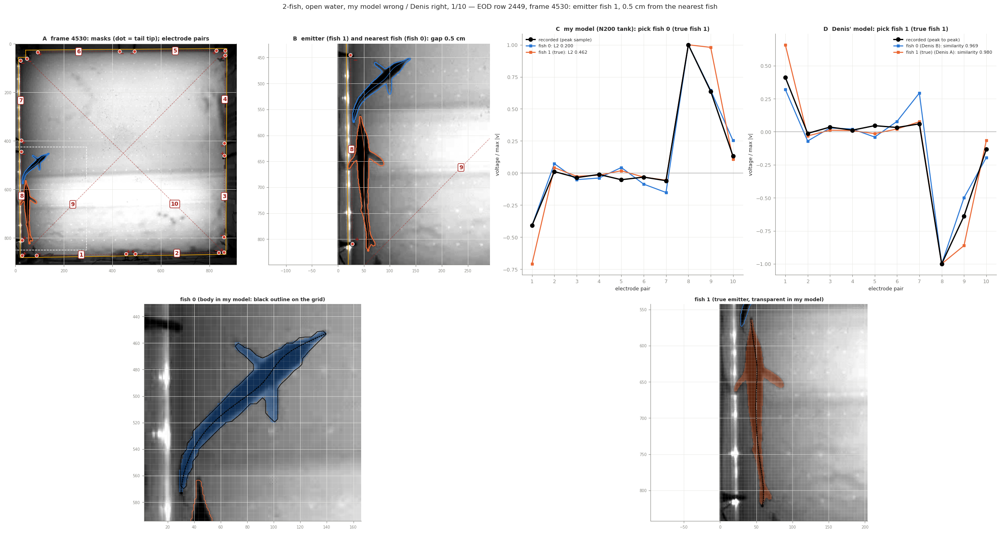

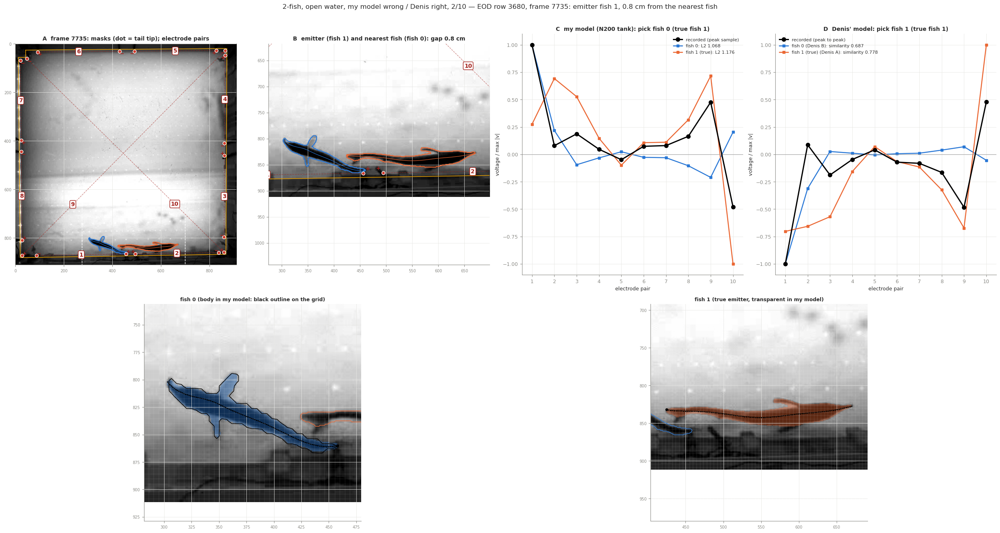

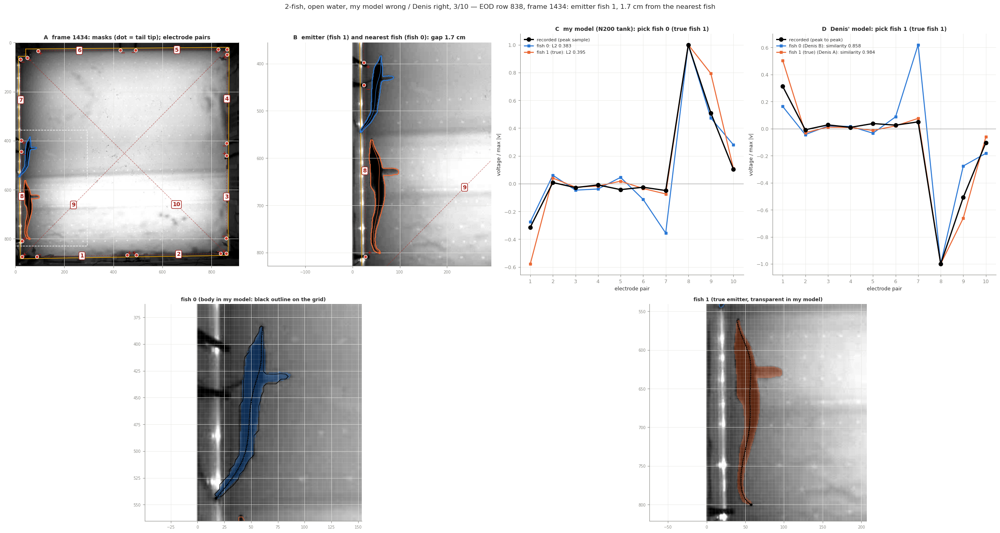

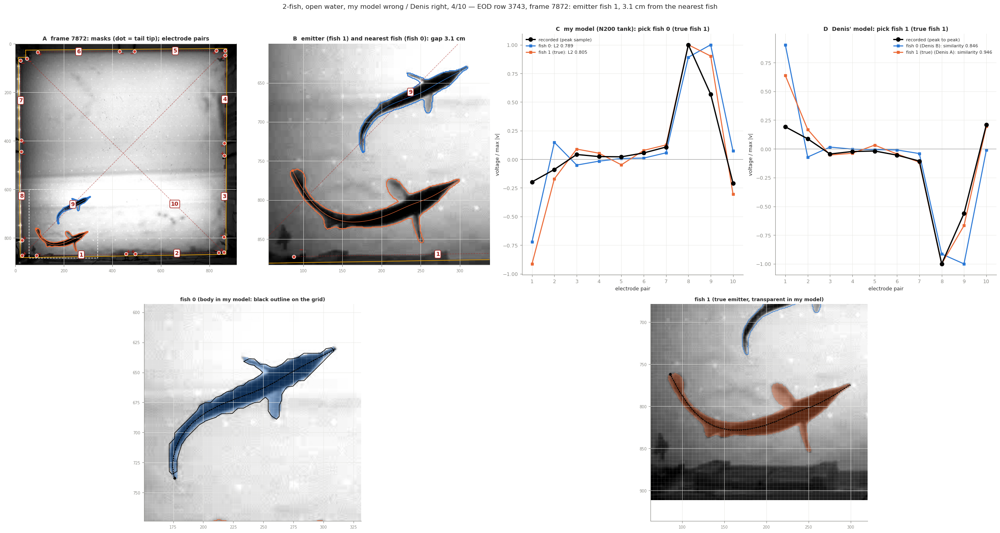

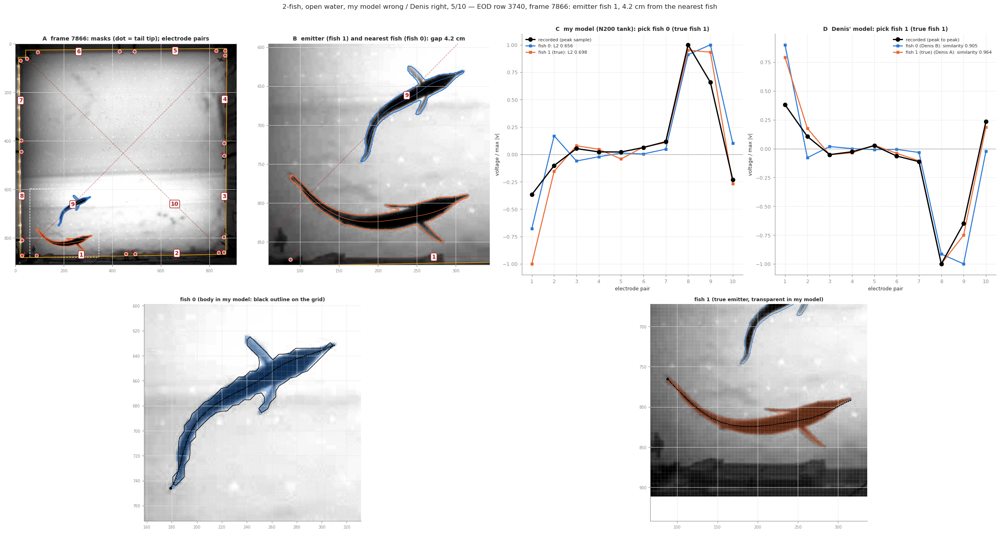

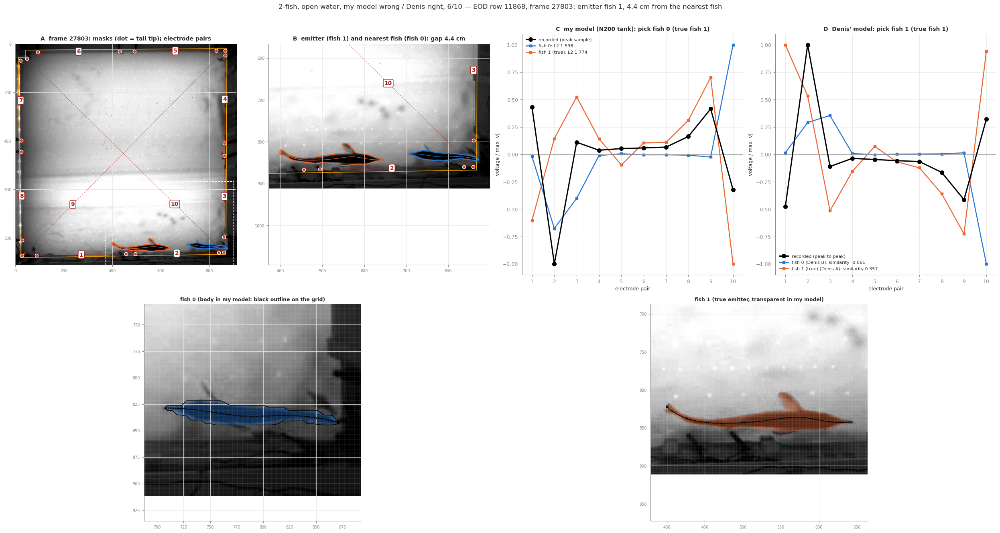

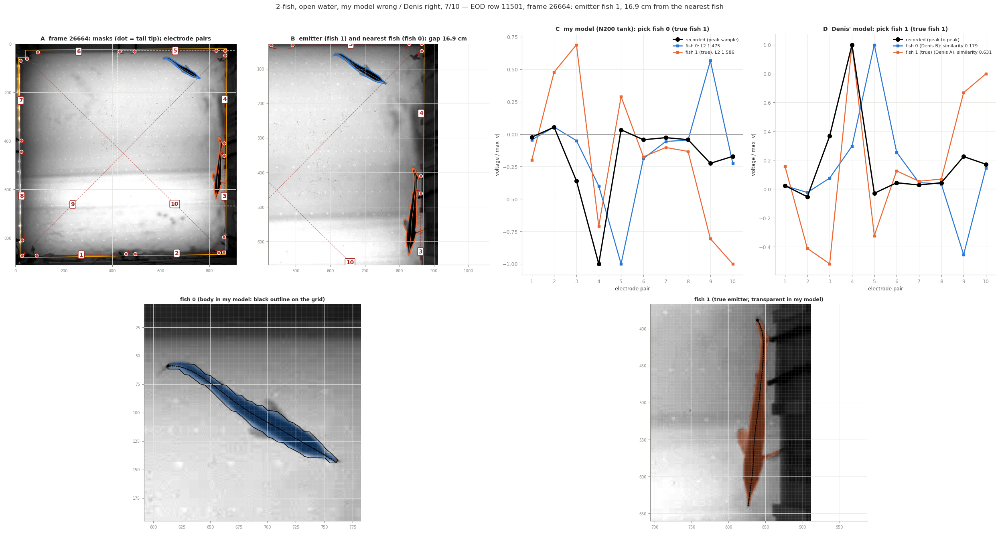

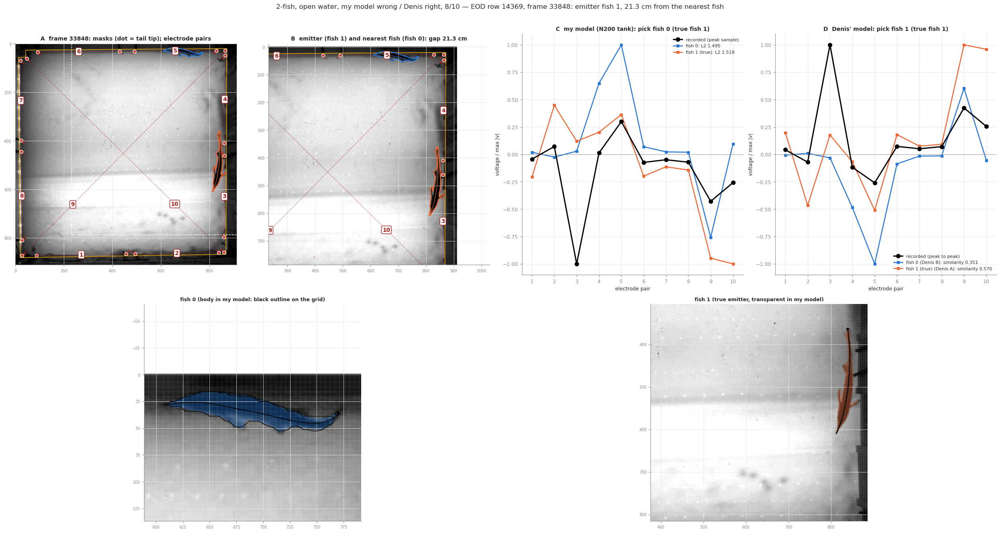

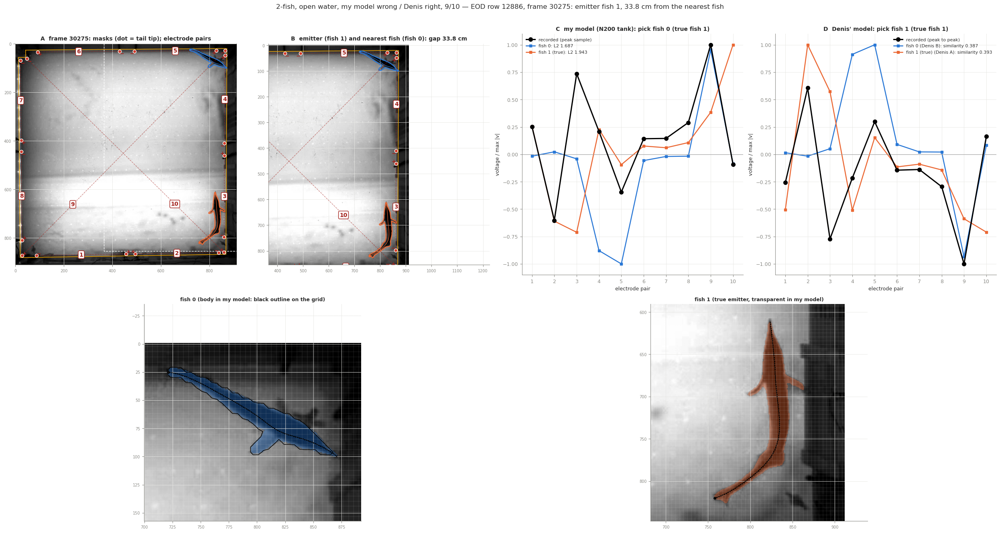

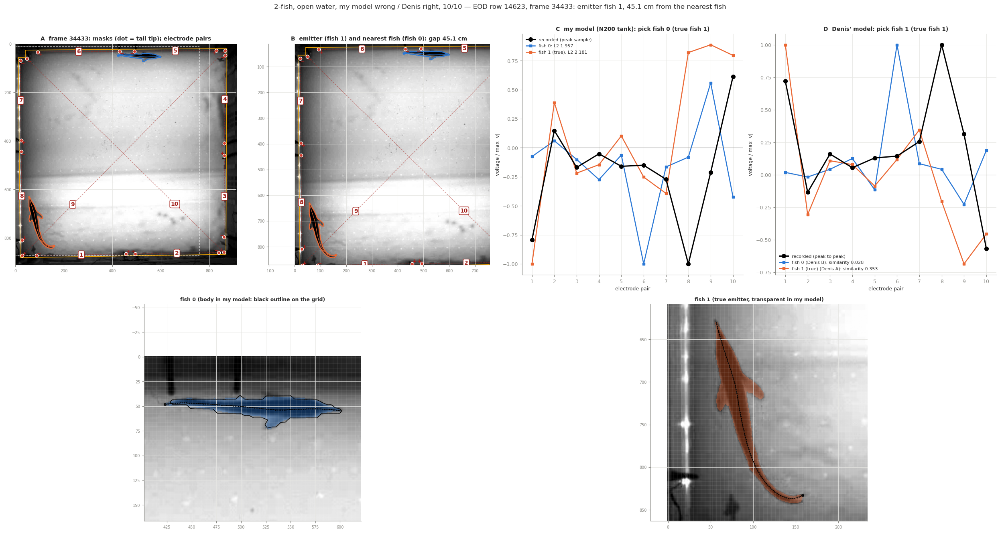

In [4]:
rows_2 = [plot_example('2-fish', n, info) for n, (_, info) in enumerate(SEL['2-fish'].iterrows(), 1)]

### 3-fish: open-water EODs, my model wrong and Denis' right (sorted by the gap to the nearest fish)

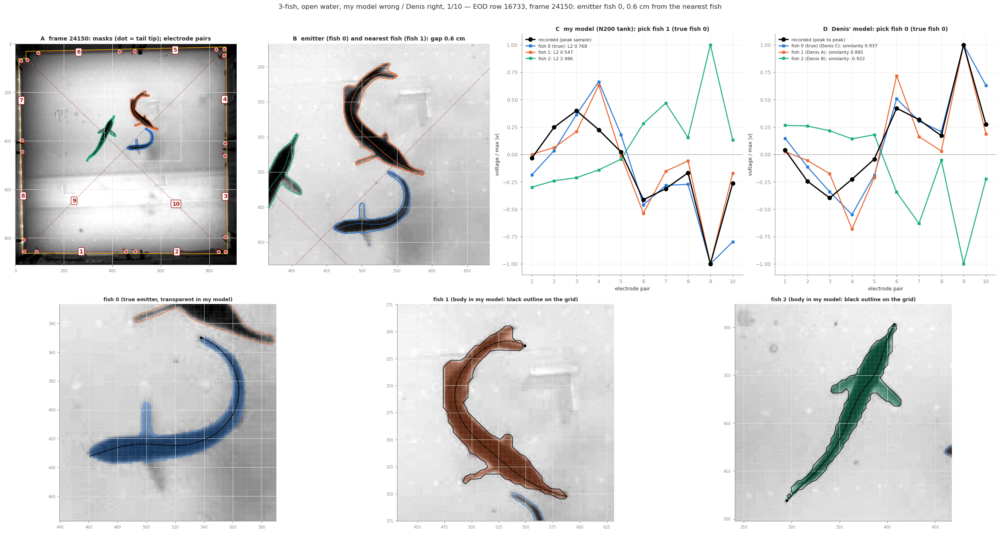

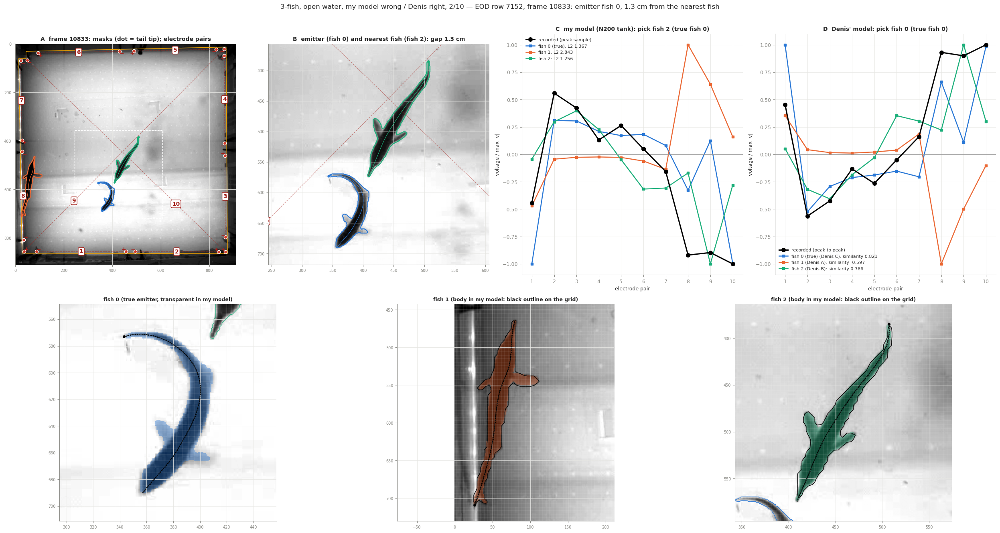

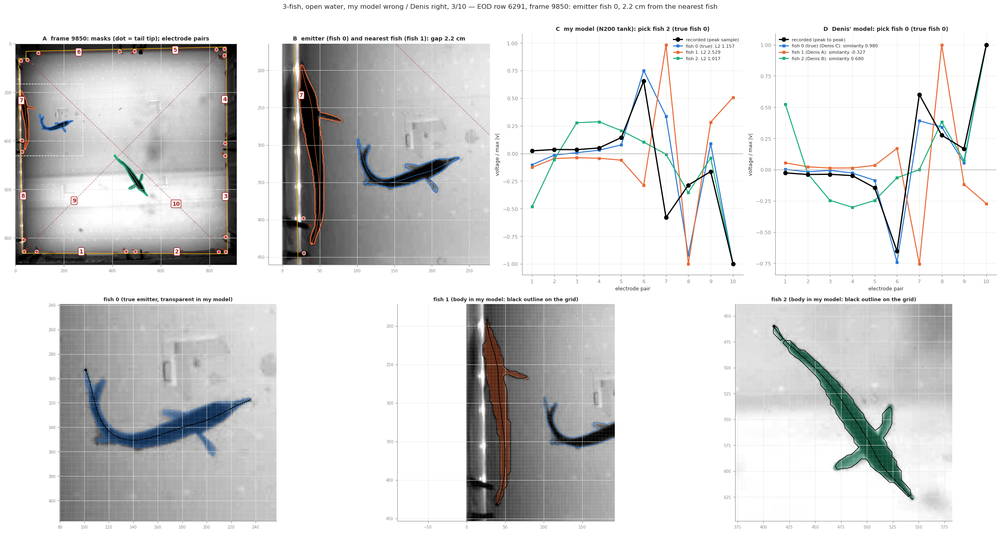

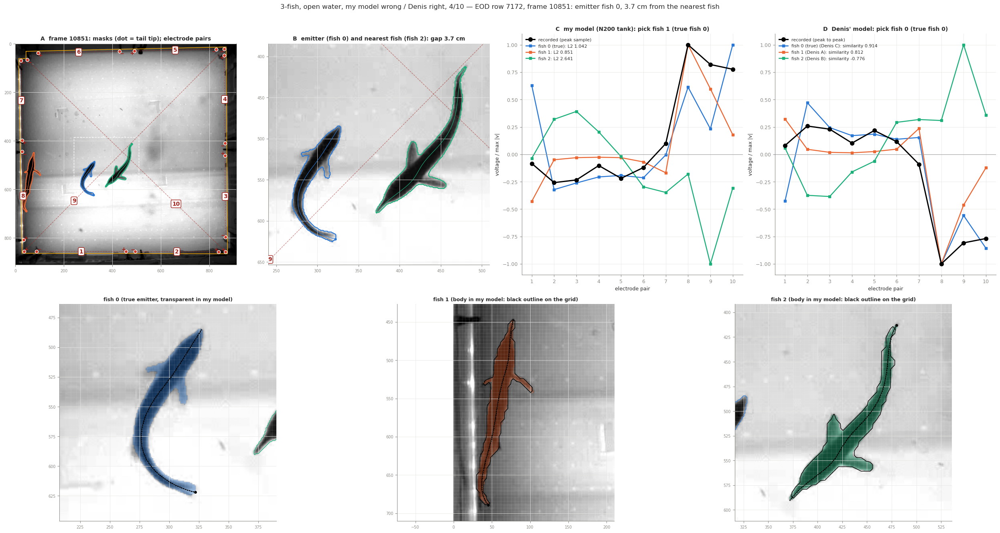

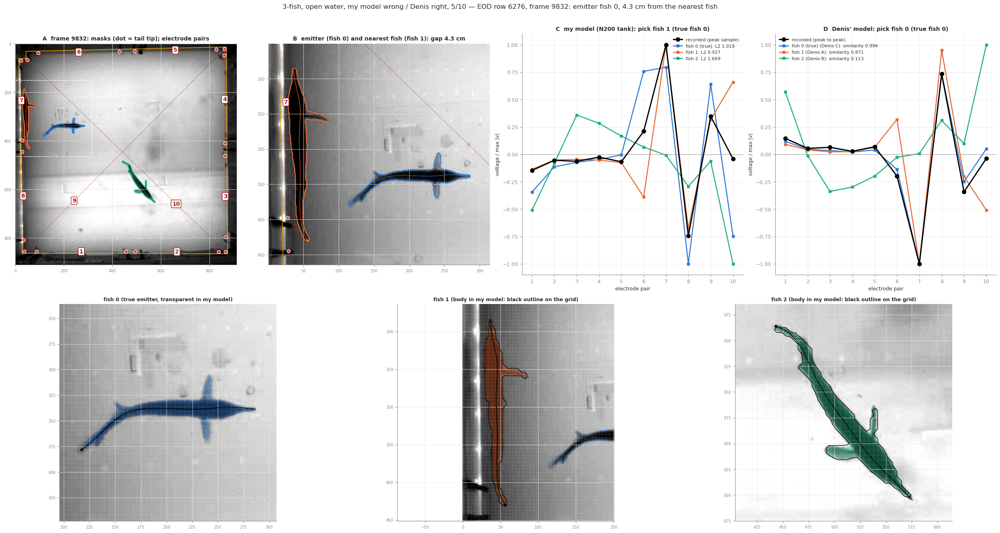

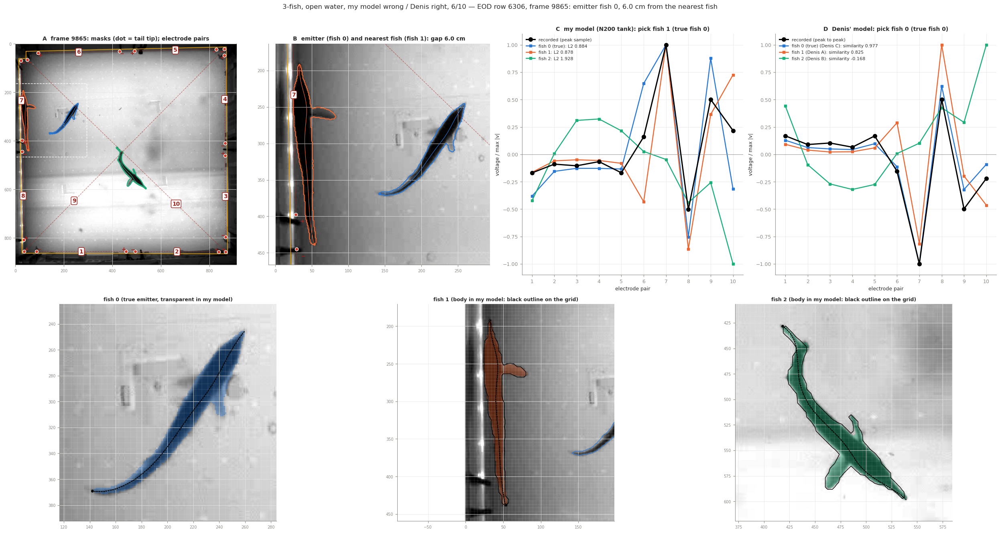

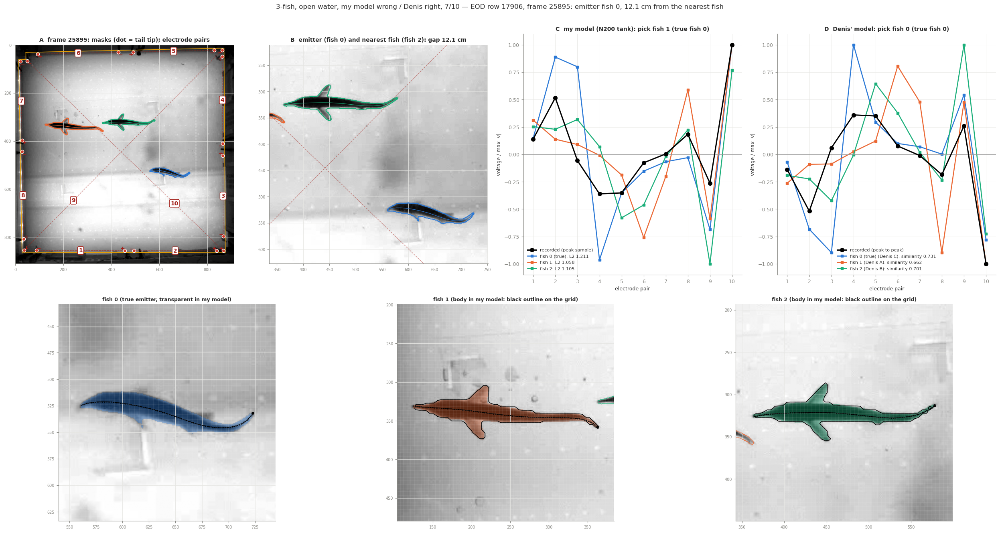

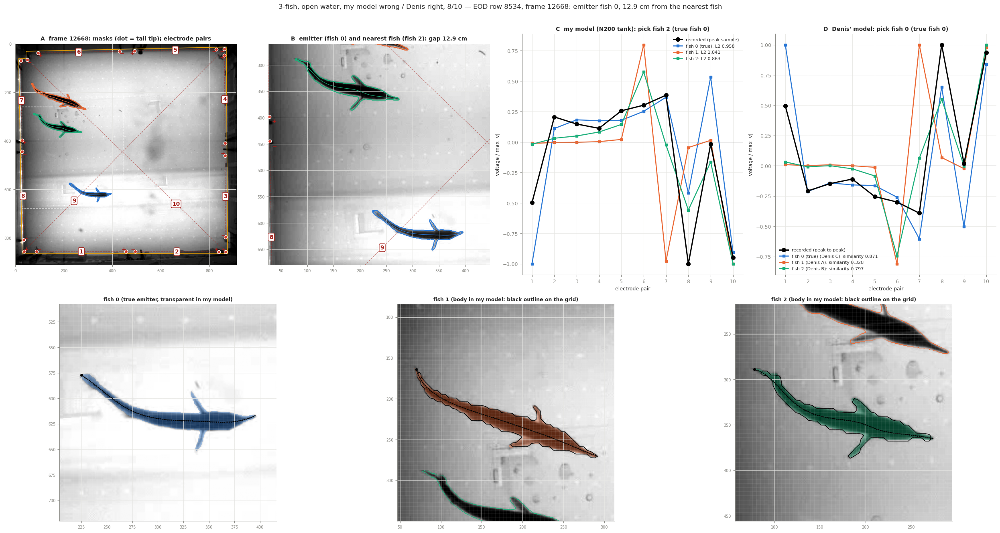

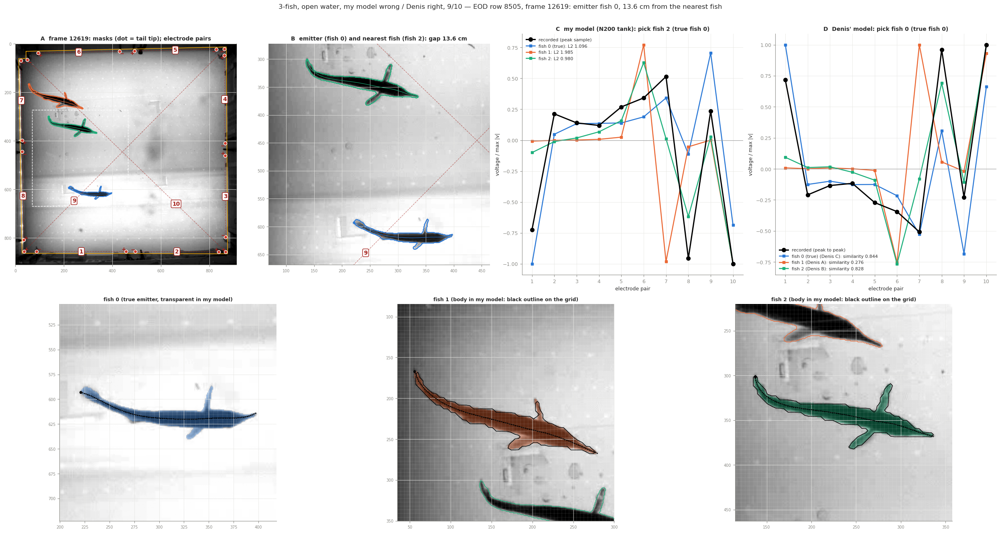

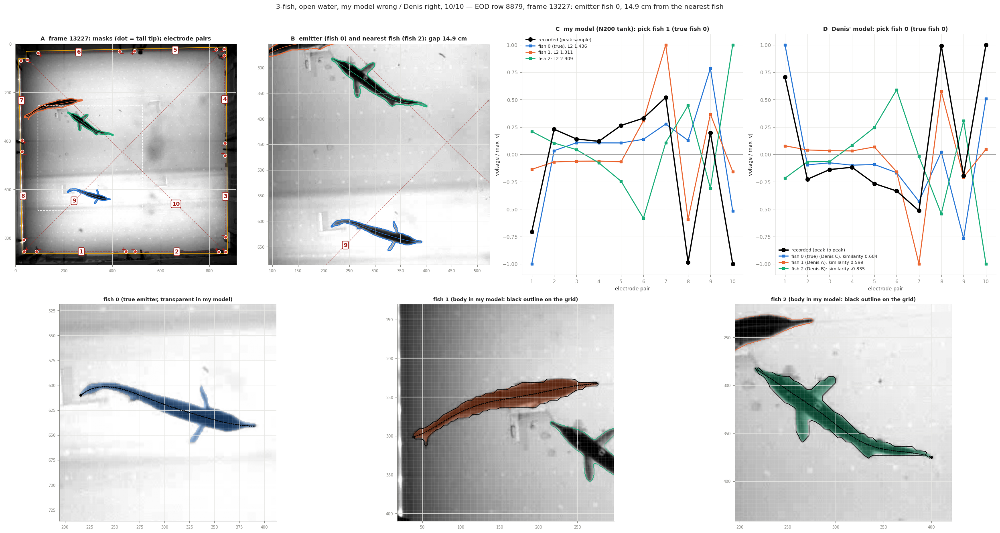

In [5]:
rows_3 = [plot_example('3-fish', n, info) for n, (_, info) in enumerate(SEL['3-fish'].iterrows(), 1)]

## 3. Summary of the 20 examples

In [6]:
S = pd.DataFrame(rows_2 + rows_3); S.to_csv(f"{OUT['3-fish']}/summary_open_water.csv", index=False)
display(S.round(3))

,rec,eod_row,Frame,gap_cm,nearest_fish,my_pick,denis_pick,my L2 fish 0,my L2 fish 1,Denis similarity fish 0,Denis similarity fish 1,my L2 fish 2,Denis similarity fish 2
0,2-fish,2449,4530,0.465,0,0,1,0.200,0.462,0.969,0.980,NaN,NaN
1,2-fish,3680,7735,0.814,0,0,1,1.068,1.176,0.687,0.778,NaN,NaN
2,2-fish,838,1434,1.722,0,0,1,0.383,0.395,0.858,0.984,NaN,NaN
3,2-fish,3743,7872,3.126,0,0,1,0.789,0.805,0.846,0.946,NaN,NaN
4,2-fish,3740,7866,4.238,0,0,1,0.656,0.698,0.905,0.964,NaN,NaN
5,2-fish,11868,27803,4.402,0,0,1,1.598,1.774,-0.061,0.357,NaN,NaN
6,2-fish,11501,26664,16.873,0,0,1,1.475,1.586,0.179,0.631,NaN,NaN
7,2-fish,14369,33848,21.287,0,0,1,1.495,1.518,0.351,0.570,NaN,NaN
8,2-fish,12886,30275,33.808,0,0,1,1.687,1.943,0.387,0.393,NaN,NaN
9,2-fish,14623,34433,45.141,0,0,1,1.957,2.181,0.028,0.353,NaN,NaN


## 4. Findings

**Who these EODs are.**
- On clean good frames the emitter is in open water in 3,337 (2-fish) and 8,033 (3-fish) EODs. My model is wrong and Denis' right
  on 32 and 60 of them; the other way round on 7 and 10.
- These EODs are much closer to another fish than open water in general. The median gap emitter → nearest fish is 4.3 cm (2-fish)
  and 4.9 cm (3-fish), against 18.4 and 11.4 cm for all open-water EODs.
- In them the true emitter's model fits the recording poorly (median L2 1.0–1.2, against 0.3–0.44 on correct open-water EODs),
  and the winning fish is only slightly better.

**What was ruled out** (tested on every open-water clean-good EOD):
- *The fixed sign.* Flipping the model's sign makes the true emitter fit much worse in 97–98 % of these EODs (median L2 2.6–2.9).
- *The recorded pattern.* Using the rank-1 pattern of the 25 samples, or Denis' signed peak-to-peak, instead of the single peak
  sample fixes 0 of the 92 EODs.

**What explains them:**
- **2-fish: the comparison measure.** Ranking the same model patterns by cosine similarity (as Denis does) instead of L2 on the
  max-|v| = 1 patterns fixes 22 of 32. Clean-good accuracy goes from 98.96 to 99.40 % (open water 98.53 → 99.22 %), level with
  Denis' 99.43 %. For 3-fish cosine changes little (98.33 → 98.35 %; fixes 16 of 60).
- **3-fish: the other fish's bodies.** Re-solving with the other fish left out (each candidate a bare source in the tank, as in
  Denis' model) fixes 48 of 60 (28 of 31 with the fish within 5 cm, 20 of 29 farther apart). It keeps 299 of a random 300 open-water
  EODs that were right. For 2-fish it fixes only 4 of 32 (and keeps 300 of 300).
  The bodies are conducting (interior 100 × water) inside a resistive skin. When a fish is close, its body bends the emitter's
  field strongly in my model, and the recordings do not show that. Either the bodies are too strong (interior conductivity, skin,
  2D columns over the full water depth) or the masks of nearby fish are too large (fins, merged shadows).

**Next:** run every EOD of both controls (1) with cosine similarity, which needs no new solves, and (2) without the other fish's
bodies, and with weaker bodies (e.g. lower interior conductivity), to see whether this closes the gap to Denis everywhere and not
only in open water.